# Análisis de series temporales: ejercicio 1

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import kpss, adfuller, acf
from statsmodels.stats.diagnostic import het_arch

El archivo "dataset.csv" contiene datos ambientales de una sala obtenido mediante un sensor. Además, se ha añadido una variable que categoriza la ocupación de esa sala para cada uno de los instantes temporales contenidos en la serie. El set de datos contiene la siguiente información:
- date: year-month-day hour:minute:second
- Temperature (Temperatura), en Celsius
- Relative Humidity (Humedad relativa) en %
- Light (Luminosidad), en Lux
- CO2, en ppm
- Humidity Ratio (Raio de humedad), derivado de la temperatura y la humedad relativa, en kgwater-vapor/kg-air
- Occupancy, 0 or 1, 0 para habitación NO ocupada, 1 para habitación ocupada

En base a los datos atmosféricos de la sala, queremos predecir si está ocupada o no. Teniendo esta en cuenta:
- ¿Cuál es la variable objetivo?
- Haz una selección de variables mediante el [cálculo de coeficientes de correlación](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html). En caso de querer representar el diagrama de correlación, utiliza la función [seaborn.heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html).
- Para la variable "Temperature", descomponer ([seasonal_decompose](https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html)) la serie temporal (representar la descomposición para su visualización) y responder a las siguientes preguntas:
    - ¿Presenta tendencia la serie temporal?
    - ¿Es estacional la serie temporal?
    - ¿Se detectan puntos de impacto?
    - Analiza la estacionariedad del residuo

Para saber el número de puntos que tiene un cierto intervalo temporal, y poder así hacer una mejor definición del periodo, se puede hacer uso de la librería [pandas.DaraFrame.resample](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html). 




In [11]:
df=pd.read_csv("data.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.set_index('date') 


Variable objetivo: Occupancy
Occupancy
0    0.789889
1    0.210111
Name: proportion, dtype: float64


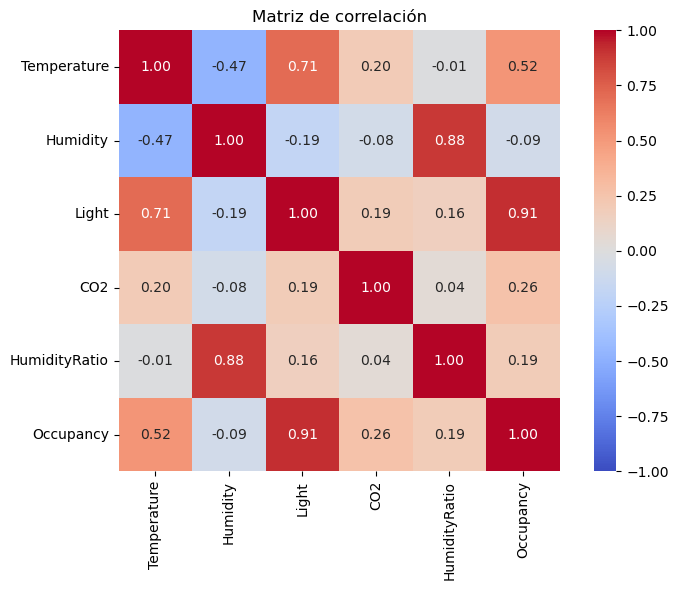


Correlación con la variable objetivo:
Light            0.914556
Temperature      0.521781
CO2              0.261917
HumidityRatio    0.190143
Humidity        -0.087762
Name: Occupancy, dtype: float64

Variables candidatas (|r| >= 0.3): ['Light', 'Temperature']
Variables seleccionadas (sin multicolinealidad): ['Light', 'Temperature']


In [12]:
target = "Occupancy"          # 0 = sala no ocupada, 1 = ocupada (clasificación binaria)
features = [c for c in df.columns if c != target]
print(f"\nVariable objetivo: {target}")
print(df[target].value_counts(normalize=True))

# ------------------------------------------------------------
# Selección de variables por correlación
# ------------------------------------------------------------
corr = df.corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

corr_target = corr[target].drop(target).sort_values(key=abs, ascending=False)
print("\nCorrelación con la variable objetivo:")
print(corr_target)

# Umbral de relevancia respecto al objetivo
umbral = 0.3
candidatas = corr_target[corr_target.abs() >= umbral].index.tolist()

# Eliminar redundancia: si dos candidatas están muy correlacionadas entre sí (> 0.9),
# nos quedamos con la que más correlaciona con el objetivo
seleccionadas = []
for f in candidatas:                      # ya ordenadas por |corr| con el objetivo
    if all(abs(corr.loc[f, s]) < 0.9 for s in seleccionadas):
        seleccionadas.append(f)

print(f"\nVariables candidatas (|r| >= {umbral}): {candidatas}")
print(f"Variables seleccionadas (sin multicolinealidad): {seleccionadas}")


Intervalos entre muestras más frecuentes:
 date
0 days 00:01:00    5849
0 days 00:00:59    1951
0 days 00:01:01    1951
Name: count, dtype: int64

Puntos por día:
 date
2015-02-11     552
2015-02-12    1440
2015-02-13    1440
2015-02-14    1440
2015-02-15    1440
2015-02-16    1440
2015-02-17    1440
2015-02-18     560
Freq: D, Name: Temperature, dtype: int64

Puntos por hora (media): 59.46341463414634

Periodo usado: 1440 observaciones (1 día)


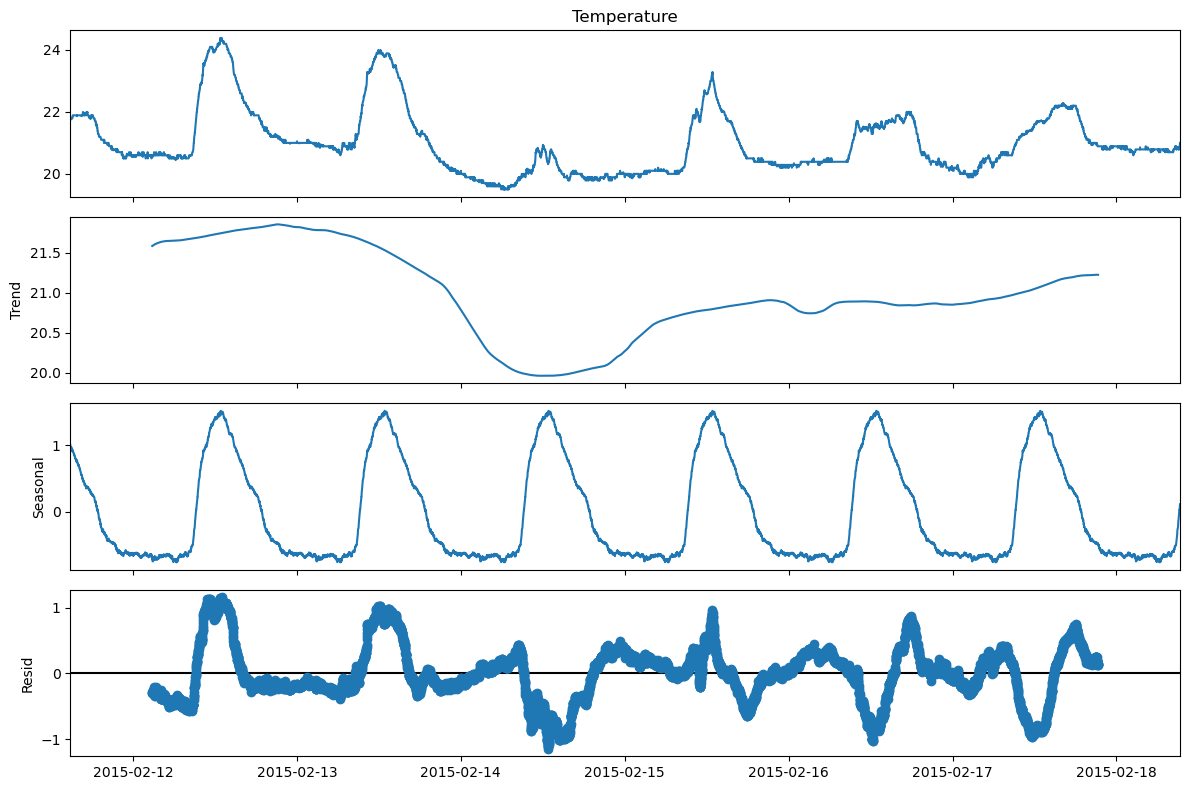

In [13]:
# ------------------------------------------------------------
# Descomposición de la serie temporal de "Temperature"
# ------------------------------------------------------------
# 3.1 Frecuencia de muestreo y definición del periodo
dt = df.index.to_series().diff().value_counts().head()
print("\nIntervalos entre muestras más frecuentes:\n", dt)

pts_por_dia = df["Temperature"].resample("D").count()
pts_por_hora = df["Temperature"].resample("h").count()
print("\nPuntos por día:\n", pts_por_dia)
print("\nPuntos por hora (media):", pts_por_hora.mean())

# Regularizar la serie a frecuencia fija (1 minuto) e interpolar huecos
freq = pd.infer_freq(df.index[:50]) or "min"
temp = df["Temperature"].asfreq(freq).interpolate(method="time")

# Periodo = nº de observaciones en un ciclo diario (1440 si hay 1 muestra/min)
periodo = int(pd.Timedelta("1D") / pd.Timedelta(temp.index.freq))
print(f"\nPeriodo usado: {periodo} observaciones (1 día)")

# 3.2 Descomposición
dec = seasonal_decompose(temp, model="additive", period=periodo)

fig = dec.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

In [14]:
# ------------------------------------------------------------
# 3.3 ¿Presenta tendencia?
# ------------------------------------------------------------
trend = dec.trend.dropna()
x = np.arange(len(trend))
pendiente, intercepto = np.polyfit(x, trend.values, 1)
print(f"\nPendiente de la tendencia: {pendiente:.6f} °C/muestra "
      f"({pendiente * periodo:.3f} °C/día)")
print(f"Variación total de la tendencia: {trend.max() - trend.min():.2f} °C")

# Contraste ADF/KPSS sobre la serie original (con tendencia determinista)
print("KPSS (trend='ct') serie original p-valor:",
      round(kpss(temp, regression="ct", nlags="auto")[1], 4))


Pendiente de la tendencia: -0.000096 °C/muestra (-0.139 °C/día)
Variación total de la tendencia: 1.90 °C
KPSS (trend='ct') serie original p-valor: 0.01


C:\Users\maren\AppData\Local\Temp\ipykernel_22520\4123082166.py:13: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  round(kpss(temp, regression="ct", nlags="auto")[1], 4))
C:\Users\maren\AppData\Local\Temp\ipykernel_22520\4123082166.py:13: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  round(kpss(temp, regression="ct", nlags="auto")[1], 4))



Fuerza de estacionalidad: 0.768
Fuerza de tendencia:      0.677


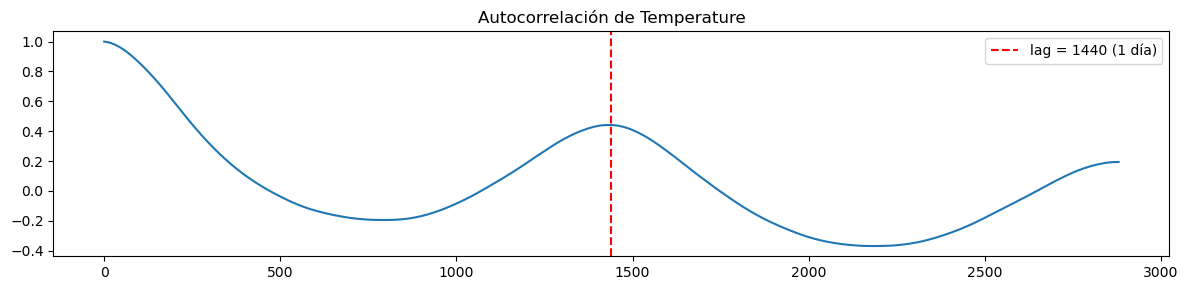

ACF en lag 1440: 0.441


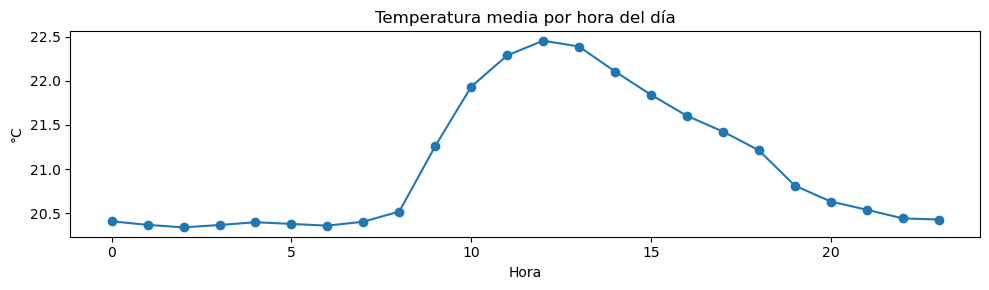

In [15]:
# ------------------------------------------------------------
# 3.4 ¿Es estacional?
# ------------------------------------------------------------
seasonal = dec.seasonal
resid = dec.resid.dropna()

# Fuerza de la estacionalidad (Hyndman): 0 = nula, 1 = muy fuerte
Fs = max(0, 1 - resid.var() / (seasonal.loc[resid.index] + resid).var())
# Fuerza de la tendencia
Ft = max(0, 1 - resid.var() / (trend.loc[resid.index] + resid).var())
print(f"\nFuerza de estacionalidad: {Fs:.3f}")
print(f"Fuerza de tendencia:      {Ft:.3f}")

# Autocorrelación: pico en el lag = periodo indica estacionalidad
nlags = min(len(temp) - 1, periodo * 2)
ac = acf(temp, nlags=nlags, fft=True)
plt.figure(figsize=(12, 3))
plt.plot(ac)
plt.axvline(periodo, color="r", ls="--", label=f"lag = {periodo} (1 día)")
plt.title("Autocorrelación de Temperature")
plt.legend()
plt.tight_layout()
plt.show()
print(f"ACF en lag {periodo}: {ac[periodo]:.3f}")

# Perfil medio diario (patrón estacional por hora)
plt.figure(figsize=(10, 3))
temp.groupby(temp.index.hour).mean().plot(marker="o")
plt.title("Temperatura media por hora del día")
plt.xlabel("Hora")
plt.ylabel("°C")
plt.tight_layout()
plt.show()


Puntos con |z|>3: 0
Outliers IQR (k=3): 0
Posibles cambios de nivel: 92


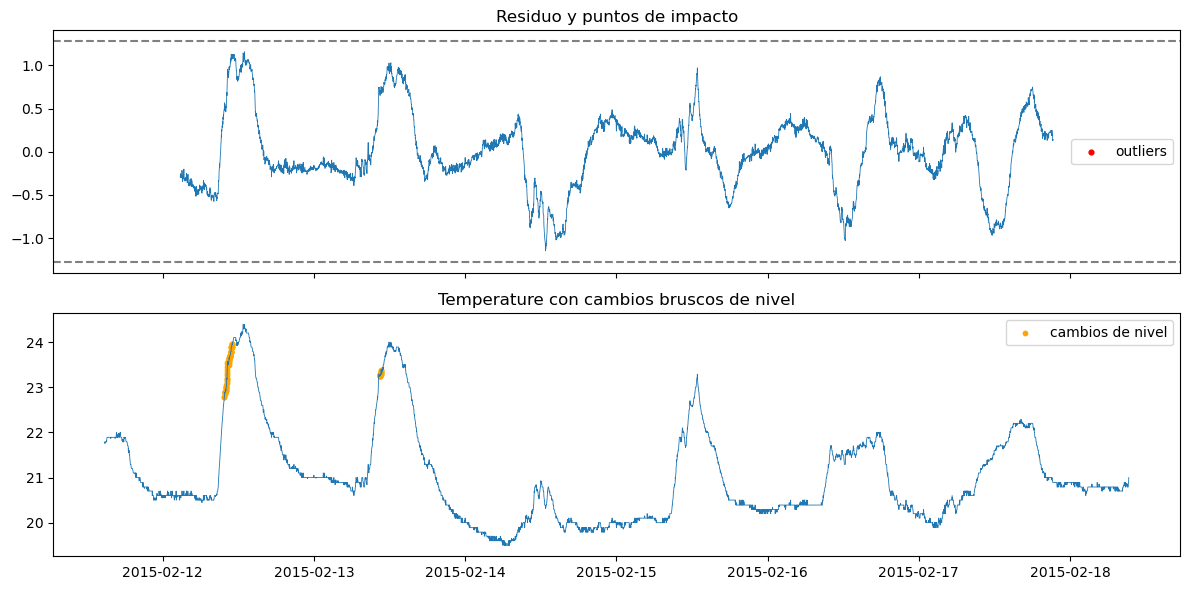

In [16]:
# ------------------------------------------------------------
# 3.5 ¿Se detectan puntos de impacto (outliers / shocks / cambios de nivel)?
# ------------------------------------------------------------
# a) Outliers en el residuo (|z| > 3 o regla IQR)
z = (resid - resid.mean()) / resid.std()
q1, q3 = resid.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = resid[(resid < q1 - 3 * iqr) | (resid > q3 + 3 * iqr)]
print(f"\nPuntos con |z|>3: {(z.abs() > 3).sum()}")
print(f"Outliers IQR (k=3): {len(outliers)}")

# b) Cambios bruscos de nivel (diferencia de medias móviles)
ventana = 60  # minutos
salto = temp.rolling(ventana).mean().diff(ventana).abs()
umbral_salto = salto.mean() + 4 * salto.std()
cambios = salto[salto > umbral_salto]
print(f"Posibles cambios de nivel: {len(cambios)}")

fig, ax = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax[0].plot(resid, lw=0.6)
ax[0].scatter(outliers.index, outliers.values, color="r", s=12, label="outliers")
ax[0].axhline(3 * resid.std(), color="gray", ls="--")
ax[0].axhline(-3 * resid.std(), color="gray", ls="--")
ax[0].set_title("Residuo y puntos de impacto")
ax[0].legend()
ax[1].plot(temp, lw=0.6)
ax[1].scatter(cambios.index, temp.loc[cambios.index], color="orange", s=10, label="cambios de nivel")
ax[1].set_title("Temperature con cambios bruscos de nivel")
ax[1].legend()
plt.tight_layout()
plt.show()


--- Estacionariedad del residuo ---
ADF  : estadístico=-3.390, p-valor=0.0113  (H0: raíz unitaria / NO estacionaria)
KPSS : estadístico=0.126, p-valor=0.1000  (H0: estacionaria)
=> El residuo es ESTACIONARIO.


C:\Users\maren\AppData\Local\Temp\ipykernel_22520\2780995716.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(resid, autolag="AIC")
C:\Users\maren\AppData\Local\Temp\ipykernel_22520\2780995716.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, *_ = kpss(resid, regression="c", nlags="auto")
C:\Users\maren\AppData\Local\Temp\ipykernel_22520\2780995716.py:5: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=Tru

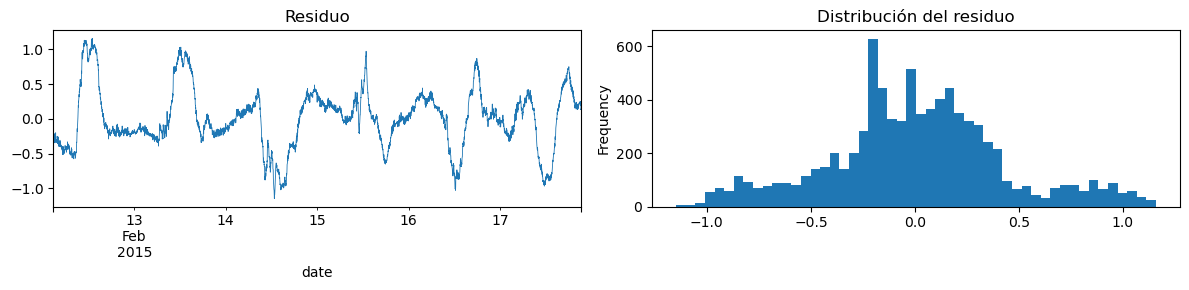

In [17]:
# ------------------------------------------------------------
# 3.6 Estacionariedad del residuo (ADF + KPSS)
# ------------------------------------------------------------
adf_stat, adf_p, *_ = adfuller(resid, autolag="AIC")
kpss_stat, kpss_p, *_ = kpss(resid, regression="c", nlags="auto")

print("\n--- Estacionariedad del residuo ---")
print(f"ADF  : estadístico={adf_stat:.3f}, p-valor={adf_p:.4f}  "
      f"(H0: raíz unitaria / NO estacionaria)")
print(f"KPSS : estadístico={kpss_stat:.3f}, p-valor={kpss_p:.4f}  "
      f"(H0: estacionaria)")

if adf_p < 0.05 and kpss_p >= 0.05:
    print("=> El residuo es ESTACIONARIO.")
elif adf_p >= 0.05 and kpss_p < 0.05:
    print("=> El residuo NO es estacionario.")
else:
    print("=> Resultados contradictorios: revisar gráficamente / diferenciar.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3))
resid.plot(ax=ax[0], lw=0.6, title="Residuo")
resid.plot(kind="hist", bins=50, ax=ax[1], title="Distribución del residuo")
plt.tight_layout()
plt.show()